# Grocery Shopping Frequency & Purchasing Patterns: An Instacart Analysis

**Goal:** understand how the time between grocery orders relates to what customers buy, focusing on how the
**same customer's cart changes** between short and long ordering intervals.

| # | Question |
|---|---|
| Q1 | Do customers who shop more often buy more items overall, even if each basket is smaller? |
| Q2 | When the same customer waits longer between orders, is their basket bigger? |
| Q3 | Does the same customer's category mix (share of items) change between short and long intervals? |
| Q4 | Are categories more likely to appear, and are more aisles covered, after a long interval? Are long baskets just bigger versions of the usual cart? |

**Main focus:** the within-customer comparison (Q2-Q4), comparing each customer's short- and long-interval orders with each other.
Q1 compares different customers and is included as supporting context.

**Central finding:** shopping frequency is associated much more with *how much* customers buy than with *what categories* they buy.

**Workflow.** The full Instacart dataset (3.4M orders, 33.8M basket items) was loaded into PostgreSQL. The SQL scripts in
`sql/` clean and aggregate it into small customer-level tables, exported to `data/processed/`. This notebook loads those
tables with pandas, calculates the final metrics and draws the charts. The exported tables have one row per customer
with no customer identifiers, and they contain no raw transactions.

| Script | Purpose |
|---|---|
| `01_create_and_load.sql` | Create tables and load the raw CSVs |
| `02_data_profiling.sql` | Data-quality checks |
| `03_build_order_baskets.sql` | One row per order with known contents: items, aisles, items per category |
| `04_q1_frequency_vs_volume.sql` | Q1: each customer's first 90 days |
| `05_q2_q4_within_customer.sql` | Q2-Q4: each customer's short vs long orders, plus sensitivity checks |

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path('../data/processed')
CHARTS = Path('../charts')
CHARTS.mkdir(exist_ok=True)

pd.set_option('display.float_format', '{:,.2f}'.format)

# Chart style: one consistent look for every figure
SHORT_COLOR = '#eb6834'   # short interval (1-3 days)
LONG_COLOR = '#2a78d6'    # long interval (8-30 days)
MAIN_COLOR = '#2a78d6'
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.labelsize': 10,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'text.color': INK,
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'font.size': 10, 'legend.frameon': False, 'figure.dpi': 110,
})

def save(fig, name):
    fig.savefig(CHARTS / name, dpi=150, bbox_inches='tight')

## 1. Data overview and exclusions

Key facts from the profiling script (`02_data_profiling.sql`):

- **206,209 customers**, each with 4-100 orders (median 10). Histories are partial: order 1 is the first order *in the data*, not necessarily the customer's first order ever.
- **No calendar dates.** Time only exists as `days_since_prior_order`, so timelines are rebuilt by adding up those gaps.
- **Intervals are capped at 30 days.** 10.8% of orders show exactly 30, which really means "30 or more days".
- **75,000 `test` orders have no basket contents** and are excluded from every basket measure. Each is the customer's final order.
- No duplicate product lines, no orphan keys, and missing intervals occur only on first orders.

Orders with known basket contents, by interval group:

In [2]:
groups = pd.read_csv(DATA / 'orders_by_interval_group.csv')
labels = {'first': 'First order (no interval)', 'same_day': '0 days (same day)', 'short': '1-3 days  -> SHORT',
          'middle': '4-7 days', 'long': '8-30 days -> LONG'}
groups['interval_group'] = groups['interval_group'].map(labels)
groups['pct_of_orders'] = 100 * groups['orders'] / groups['orders'].sum()
groups.rename(columns={'avg_items_pooled': 'avg_items (all orders pooled)'})

,interval_group,orders,customers,avg_items (all orders pooled),pct_of_orders
0,First order (no interval),206209,206209,10.08,6.16
1,0 days (same day),66562,32504,7.00,1.99
2,1-3 days -> SHORT,549627,90574,7.95,16.43
3,4-7 days,982597,142443,10.67,29.37
4,8-30 days -> LONG,1541088,203017,10.66,46.06


**Exclusions for Q2-Q4.** Only *short* (1-3 days) and *long* (8-30 days) orders are compared. First orders have no interval.
Same-day orders average only 7 items and look like add-on orders, and the 4-7 day band is left out to keep the two groups
clearly separated. Capped 30-day orders stay in the long group, since "30+ days" is still a long wait.

**Pooled averages are misleading.** In the pooled table above, short-interval orders average 7.95 items against 10.66 for long
ones, but short-interval orders come mostly from the most active customers: the top 25% by order count place 85% of them (`03_build_order_baskets.sql`). That's why Q2-Q4 compare
each customer **with themselves**.

## 2. Q2: Shopping interval vs. basket size (within customer)

**Method.** 88,202 customers have at least one short (1-3 days) **and** one long (8-30 days) order, covering 1,358,167 orders. For each customer:
average basket size of their short orders, average of their long orders, and the difference (long - short).
Results are then averaged across customers, so **each customer counts equally**, however many orders they placed.

In [3]:
# One row per customer. Columns come in pairs, e.g. short_avg_basket_size and long_avg_basket_size.
# Turn 'short_avg_basket_size' into the two-level column ('avg_basket_size', 'short'),
# so w['avg_basket_size', 'short'] gives that metric for short-interval orders.
def split_short_long(df):
    df = df.copy()
    df.columns = pd.MultiIndex.from_tuples([(c.split('_', 1)[1], c.split('_', 1)[0]) for c in df.columns])
    return df

w = split_short_long(pd.read_csv(DATA / 'within_customer.csv'))
total_orders = w['n_orders', 'short'].sum() + w['n_orders', 'long'].sum()
print(f"Qualifying customers: {len(w):,} | orders compared: {total_orders:,}")
print(f"Median orders per customer: short = {w['n_orders','short'].median():.0f}, long = {w['n_orders','long'].median():.0f}")

def basket_comparison(w):
    diff = w['avg_basket_size', 'long'] - w['avg_basket_size', 'short']
    return pd.Series({
        'customers': len(w),
        'avg_short_basket': w['avg_basket_size', 'short'].mean(),
        'avg_long_basket': w['avg_basket_size', 'long'].mean(),
        'avg_difference': diff.mean(),
        'median_difference': diff.median(),
        'pct_larger_when_long': 100 * (diff > 0).mean(),
        'pct_same': 100 * (diff == 0).mean(),
        'pct_smaller_when_long': 100 * (diff < 0).mean(),
    })

two_plus = (w['n_orders', 'short'] >= 2) & (w['n_orders', 'long'] >= 2)
q2 = pd.DataFrame({'Main: >=1 order in each group': basket_comparison(w),
                   'Check: >=2 orders in each group': basket_comparison(w[two_plus])})
q2

Qualifying customers: 88,202 | orders compared: 1,358,167
Median orders per customer: short = 2, long = 9


,Main: >=1 order in each group,Check: >=2 orders in each group
customers,"88,202.00","52,567.00"
avg_short_basket,7.73,7.80
avg_long_basket,10.11,10.18
avg_difference,2.38,2.38
median_difference,1.74,1.69
pct_larger_when_long,71.41,74.26
pct_same,1.61,0.93
pct_smaller_when_long,26.98,24.82


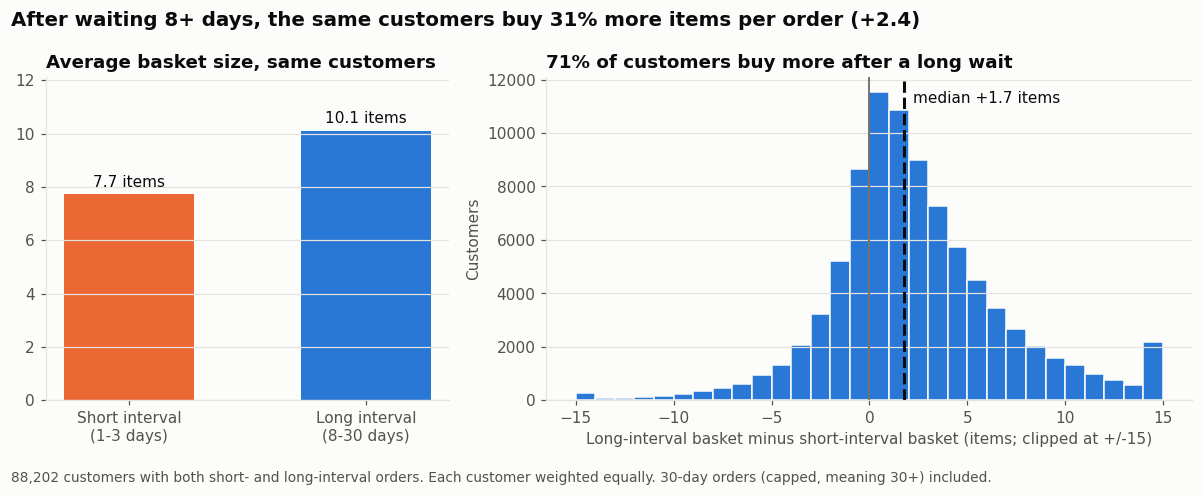

In [4]:
diff = w['avg_basket_size', 'long'] - w['avg_basket_size', 'short']
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={'width_ratios': [1, 1.6]})

ax = axes[0]
vals = [q2.iloc[1, 0], q2.iloc[2, 0]]
bars = ax.bar(['Short interval\n(1-3 days)', 'Long interval\n(8-30 days)'], vals,
              color=[SHORT_COLOR, LONG_COLOR], width=0.55)
ax.bar_label(bars, labels=[f'{v:.1f} items' for v in vals], padding=3, color=INK)
ax.set_ylim(0, max(vals) * 1.2)
ax.set_title('Average basket size, same customers', loc='left')
ax.grid(axis='x', visible=False)

ax = axes[1]
clipped = diff.clip(-15, 15)
ax.hist(clipped, bins=range(-15, 16), color=LONG_COLOR, edgecolor=SURFACE, linewidth=1)
ax.axvline(0, color=INK_2, linewidth=1)
ax.axvline(diff.median(), color=INK, linewidth=2, linestyle='--')
ax.annotate(f'median +{diff.median():.1f} items', xy=(diff.median(), ax.get_ylim()[1] * 0.92),
            xytext=(6, 0), textcoords='offset points', color=INK, fontsize=10)
ax.set_xlabel('Long-interval basket minus short-interval basket (items; clipped at +/-15)')
ax.set_ylabel('Customers')
ax.set_title(f'{(diff > 0).mean():.0%} of customers buy more after a long wait', loc='left')
ax.grid(axis='x', visible=False)

pct_more = 100 * (vals[1] / vals[0] - 1)
fig.suptitle(f'After waiting 8+ days, the same customers buy {pct_more:.0f}% more items per order (+{vals[1] - vals[0]:.1f})',
             x=0.01, ha='left', fontsize=13, fontweight='bold')
fig.text(0.01, -0.04, f'{len(w):,} customers with both short- and long-interval orders. '
         'Each customer weighted equally. 30-day orders (capped, meaning 30+) included.', color=INK_2, fontsize=9)
fig.tight_layout()
save(fig, '01_basket_size_within_customer.png')
plt.show()

In [5]:
# Sensitivity checks calculated in SQL (05_q2_q4_within_customer.sql)
pd.read_csv(DATA / 'sensitivity_checks.csv')

,check_name,customers,short_value,long_value,avg_difference
0,Q2 main (long = 8-30 days),88202,7.73,10.11,2.38
1,Q2 excluding capped 30-day orders (long = 8-29...,85890,7.75,10.15,2.40
2,Average order number (tenure stage),88202,13.93,13.79,-0.14


**Q2 findings**

- **Yes.** The same customers average **7.7 items** in short-interval orders and **10.1 items** in long-interval orders: **+2.4 items** on average (median +1.7). That's about **31% larger** (10.1 / 7.7).
- **71% of customers** have bigger long-interval baskets; 27% have smaller ones. So it's a strong typical pattern, not a rule.
- The result is **robust**: requiring 2+ orders per group gives the same +2.4, and dropping the capped 30-day orders gives +2.4 too.
- Short and long orders occur at the **same stage of a customer's history** (average order number 13.9 vs 13.8), so the gap isn't explained by customers changing over time.
- This is an observed association, not proof that waiting *causes* bigger baskets. The likely explanation runs both ways: a customer who does a big stock-up shop doesn't need to reorder for a while, and a small top-up order is often followed quickly by another.

## 3. Q3: Shopping interval vs. category composition (within customer)

**Method.** Same 88,202 customers. For each customer and interval group: *% of basket items* from each category.
For example, "of all items this customer bought in short-interval orders, 25% were fresh produce." Then averaged across customers.
Categories use Instacart's aisle classification. Organic and non-organic products are not separated.

| Category | Instacart aisles |
|---|---|
| Fresh produce | fresh fruits, fresh vegetables, packaged vegetables fruits |
| Snacks | all 7 aisles of the snacks department |
| Yogurt / Milk / Eggs | the aisle of the same name |
| Poultry | poultry counter, packaged poultry |
| Seafood | seafood counter, packaged seafood (only 0.16% of all items, so treat with caution) |

In [6]:
CATS = ['fresh_produce', 'snacks', 'yogurt', 'milk', 'eggs', 'poultry', 'seafood']
CAT_LABELS = {'fresh_produce': 'Fresh produce', 'snacks': 'Snacks', 'yogurt': 'Yogurt', 'milk': 'Milk',
              'eggs': 'Eggs', 'poultry': 'Poultry', 'seafood': 'Seafood'}

def category_table(metric):
    rows = []
    for c in CATS:
        s, l = w[f'{c}_{metric}', 'short'], w[f'{c}_{metric}', 'long']
        d = l - s
        rows.append({'category': CAT_LABELS[c], 'short_%': s.mean(), 'long_%': l.mean(),
                     'difference_pts': d.mean(), 'relative_change_%': 100 * d.mean() / s.mean(),
                     'pct_customers_higher_when_long': 100 * (d > 0).mean(),
                     'pct_customers_lower_when_long': 100 * (d < 0).mean()})
    return pd.DataFrame(rows).set_index('category')

share = category_table('share')
share

,short_%,long_%,difference_pts,relative_change_%,pct_customers_higher_when_long,pct_customers_lower_when_long
category,,,,,,
Fresh produce,24.61,25.67,1.06,4.30,51.80,42.16
Snacks,7.19,6.85,-0.34,-4.76,47.02,37.28
Yogurt,3.35,3.98,0.63,18.92,41.98,22.06
Milk,2.63,2.91,0.28,10.77,36.87,21.18
Eggs,1.28,1.47,0.19,14.43,31.44,16.21
Poultry,0.77,0.73,-0.04,-5.17,19.69,11.57
Seafood,0.17,0.14,-0.02,-14.35,6.59,3.90


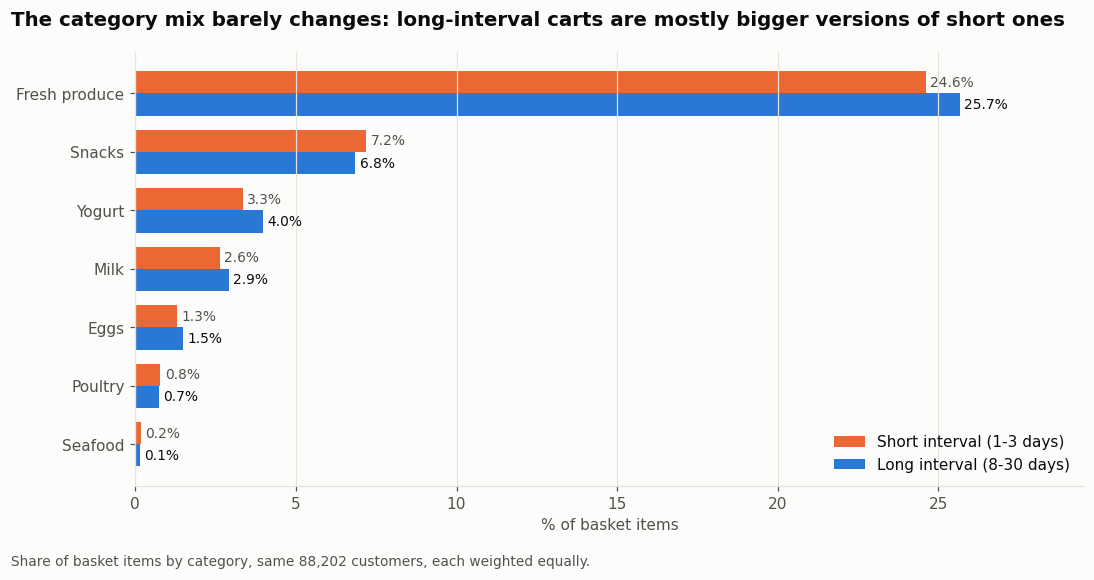

In [7]:
def paired_bars(table, title, subtitle, xlabel, fname):
    fig, ax = plt.subplots(figsize=(10, 5))
    y = range(len(table))
    h = 0.38
    b1 = ax.barh([i - h / 2 for i in y], table['short_%'], height=h, color=SHORT_COLOR, label='Short interval (1-3 days)')
    b2 = ax.barh([i + h / 2 for i in y], table['long_%'], height=h, color=LONG_COLOR, label='Long interval (8-30 days)')
    ax.bar_label(b1, labels=[f'{v:.1f}%' for v in table['short_%']], padding=3, fontsize=9, color=INK_2)
    ax.bar_label(b2, labels=[f'{v:.1f}%' for v in table['long_%']], padding=3, fontsize=9, color=INK)
    ax.set_yticks(list(y))
    ax.set_yticklabels(table.index)
    ax.invert_yaxis()
    ax.set_xlim(0, table[['short_%', 'long_%']].max().max() * 1.15)
    ax.set_xlabel(xlabel)
    ax.grid(axis='y', visible=False)
    ax.legend(loc='lower right')
    fig.suptitle(title, x=0.01, ha='left', fontsize=13, fontweight='bold')
    fig.text(0.01, -0.03, subtitle, color=INK_2, fontsize=9)
    fig.tight_layout()
    save(fig, fname)
    plt.show()

paired_bars(share,
            'The category mix barely changes: long-interval carts are mostly bigger versions of short ones',
            f'Share of basket items by category, same {len(w):,} customers, each weighted equally.',
            '% of basket items', '02_category_share.png')

**Q3 findings**

- **The mix changes only slightly.** Each category's share moves by about 1 percentage point or less between short and long orders.
- **Slightly higher share after a long wait:** fresh produce (+1.1 pts), yogurt (+0.6), milk (+0.3), eggs (+0.2). These everyday staples make up a little more of the cart.
- **Slightly lower share:** snacks (-0.3 pts). Poultry and seafood are essentially unchanged.
- For most categories, the median customer shows **no change at all** (difference = 0), because many customers rarely buy a given category.
- Overall, a long-interval basket isn't a different kind of shop. It's mostly the same mix with more items, tilted a little towards staples.

## 4. Q4: Category presence and basket diversity (within customer)

**Presence:** for each customer, the % of their short orders (and of their long orders) that contain at least one item from the category.
**Diversity:** the average number of different aisles (out of 134) in a basket.

In [8]:
presence = category_table('presence')
presence

,short_%,long_%,difference_pts,relative_change_%,pct_customers_higher_when_long,pct_customers_lower_when_long
category,,,,,,
Fresh produce,65.15,71.50,6.35,9.75,40.47,31.19
Snacks,32.06,37.20,5.14,16.04,48.49,32.00
Yogurt,17.68,25.78,8.10,45.79,43.35,18.77
Milk,16.88,24.21,7.33,43.44,39.09,17.17
Eggs,9.66,14.40,4.73,48.96,32.84,14.00
Poultry,5.67,7.18,1.51,26.54,20.35,10.46
Seafood,1.23,1.48,0.25,20.11,6.72,3.70


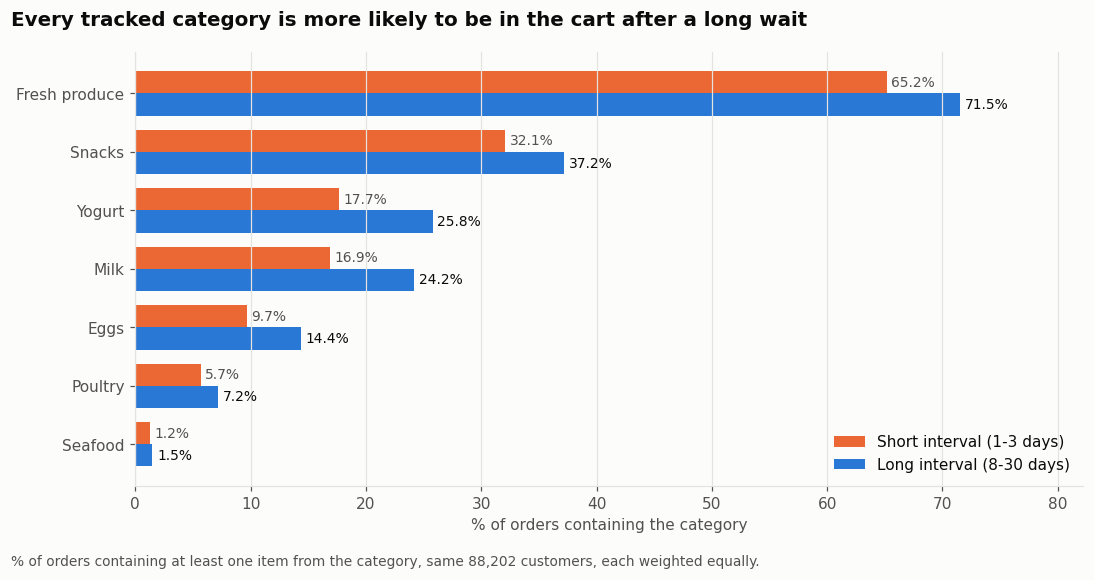

In [9]:
paired_bars(presence,
            'Every tracked category is more likely to be in the cart after a long wait',
            f'% of orders containing at least one item from the category, same {len(w):,} customers, each weighted equally.',
            '% of orders containing the category', '03_category_presence.png')

In [10]:
aisle_diff = w['avg_distinct_aisles', 'long'] - w['avg_distinct_aisles', 'short']
print(f"Distinct aisles per basket: short {w['avg_distinct_aisles','short'].mean():.2f} | "
      f"long {w['avg_distinct_aisles','long'].mean():.2f} | difference +{aisle_diff.mean():.2f} "
      f"(median +{aisle_diff.median():.2f}); {100*(aisle_diff > 0).mean():.0f}% of customers higher when long")

# Aisles per item: does a long basket spread across more aisles relative to its size?
for g in ['short', 'long']:
    print(f"  aisles per 10 items ({g}): {10 * (w['avg_distinct_aisles', g] / w['avg_basket_size', g]).mean():.2f}")

Distinct aisles per basket: short 5.76 | long 7.26 | difference +1.50 (median +1.15); 70% of customers higher when long
  aisles per 10 items (short): 7.92
  aisles per 10 items (long): 7.55


**Bigger version of the usual cart, or a different mix?** More items naturally reach more aisles, so a fair test compares
baskets **of the same size**. Two checks follow:
1. Average distinct aisles at each basket size (1-30 items), short vs long orders, for the qualifying customers.
2. Within-customer comparison using only baskets of 5-10 items (52,162 customers with both short and long baskets in that range).

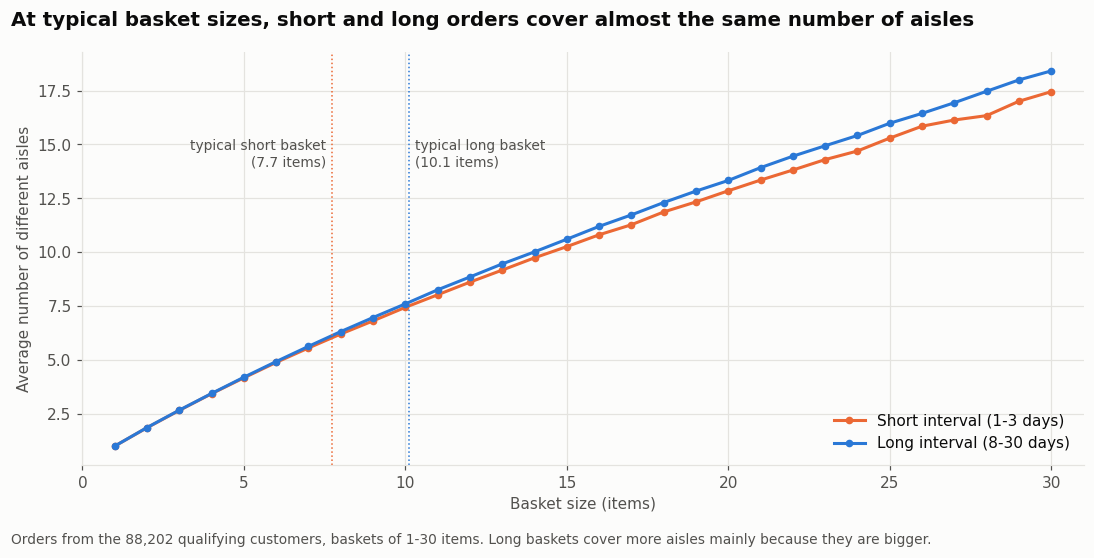

In [11]:
by_size = pd.read_csv(DATA / 'aisles_by_basket_size.csv').pivot(index='n_items', columns='interval_group',
                                                                 values='avg_distinct_aisles')
fig, ax = plt.subplots(figsize=(10, 4.8))
ax.plot(by_size.index, by_size['short'], color=SHORT_COLOR, linewidth=2, marker='o', markersize=4, label='Short interval (1-3 days)')
ax.plot(by_size.index, by_size['long'], color=LONG_COLOR, linewidth=2, marker='o', markersize=4, label='Long interval (8-30 days)')
avg_s, avg_l = w['avg_basket_size', 'short'].mean(), w['avg_basket_size', 'long'].mean()
for v, c, lab, ha, dx in [(avg_s, SHORT_COLOR, 'typical short basket', 'right', -4),
                          (avg_l, LONG_COLOR, 'typical long basket', 'left', 4)]:
    ax.axvline(v, color=c, linewidth=1, linestyle=':')
    ax.annotate(f'{lab}\n({v:.1f} items)', xy=(v, 14), xytext=(dx, 0), textcoords='offset points',
                fontsize=9, color=INK_2, ha=ha)
ax.set_xlabel('Basket size (items)')
ax.set_ylabel('Average number of different aisles')
ax.set_xlim(0, 31)
ax.legend(loc='lower right')
fig.suptitle('At typical basket sizes, short and long orders cover almost the same number of aisles',
             x=0.01, ha='left', fontsize=13, fontweight='bold')
fig.text(0.01, -0.03, f'Orders from the {len(w):,} qualifying customers, baskets of 1-30 items. '
         'Long baskets cover more aisles mainly because they are bigger.', color=INK_2, fontsize=9)
fig.tight_layout()
save(fig, '04_aisles_by_basket_size.png')
plt.show()

In [12]:
sm = split_short_long(pd.read_csv(DATA / 'within_customer_size_matched.csv'))
sm_diff = sm['avg_distinct_aisles', 'long'] - sm['avg_distinct_aisles', 'short']
pd.DataFrame({
    'customers': [len(sm)] * 2,
    'avg_basket_size': [sm['avg_basket_size', 'short'].mean(), sm['avg_basket_size', 'long'].mean()],
    'avg_distinct_aisles': [sm['avg_distinct_aisles', 'short'].mean(), sm['avg_distinct_aisles', 'long'].mean()],
}, index=['short (5-10 item baskets)', 'long (5-10 item baskets)'])

,customers,avg_basket_size,avg_distinct_aisles
short (5-10 item baskets),52162,7.10,5.60
long (5-10 item baskets),52162,7.41,5.87


**Q4 findings**

- **Presence:** every tracked category is more likely to appear after a long interval. The biggest increases are yogurt (17.7% → 25.8% of orders), milk (16.9% → 24.2%), fresh produce (65.2% → 71.5%) and snacks (32.1% → 37.2%).
- **Diversity:** long-interval baskets cover **7.3 aisles vs 5.8**, +1.5 aisles, and 70% of customers cover more aisles after a long wait.
- **Mostly bigger, not different.** At the same basket size the two lines almost overlap up to about 10 items, where most baskets fall. For large baskets (15+ items) long orders reach slightly more aisles (about 0.5-1 more). With only 5-10 item baskets, long orders cover 5.9 aisles vs 5.6, and part of even that small gap comes from those long baskets being slightly bigger (7.4 vs 7.1 items).
- So the higher presence rates mostly reflect **more items in the cart**, while category *shares* (Q3) stay close to the customer's usual mix. Long-interval carts look like a **fuller version of the usual shop**, with a slight extra tilt towards staples like produce, dairy and eggs.

## 5. Supporting context, Q1: shopping frequency vs. total purchasing volume

The main analysis looks *within* customers. This section steps back and compares *different* customers: do people who shop more often buy more overall?

**Method.** A comparable observation period: each customer's **first 90 days** of observed history (day 0 = first observed order).

- **Eligible:** customers whose history continues past day 90, so the full window is observed (149,635 customers). All orders inside the window have known baskets.
- **Frequency segment:** number of orders placed in the 90 days (4-5, 6-8, 9-12, 13+).
- **Main results:** customers with **no capped 30-day gap inside the window** (63,127), so their day numbers are exact. All 149,635 customers are shown as a sensitivity check.
- Because no gap can exceed 30, *every* customer seems to order at least every 30 days, so at least 4 times in 90 days. Customers who truly shop less than monthly can't be identified, which is why the lowest segment starts at 4-5 orders.

In [13]:
q1 = pd.read_csv(DATA / 'q1_customer_window.csv')
seg_order = ['4-5 orders', '6-8 orders', '9-12 orders', '13+ orders']

def q1_summary(df):
    return (df.groupby('frequency_segment')
              .agg(customers=('orders_in_window', 'size'),
                   avg_orders=('orders_in_window', 'mean'),
                   avg_basket_size=('avg_basket_size', 'mean'),
                   median_basket_size=('avg_basket_size', 'median'),
                   avg_items_90d=('items_in_window', 'mean'),
                   median_items_90d=('items_in_window', 'median'))
              .reindex(seg_order))

q1_exact = q1[q1['has_capped_gap'] == 0]
print(f"Eligible customers: {len(q1):,} | exact timing (main): {len(q1_exact):,}")
q1_main = q1_summary(q1_exact)
q1_main

Eligible customers: 149,635 | exact timing (main): 63,127


,customers,avg_orders,avg_basket_size,median_basket_size,avg_items_90d,median_items_90d
frequency_segment,,,,,,
4-5 orders,5256,4.74,10.35,9.20,49.06,43.00
6-8 orders,18254,7.04,10.54,9.50,74.19,67.00
9-12 orders,20241,10.36,10.70,9.70,110.93,100.00
13+ orders,19376,18.17,9.86,8.93,174.68,155.00


In [14]:
# Sensitivity check: all eligible customers, including those with a capped gap
q1_summary(q1)

,customers,avg_orders,avg_basket_size,median_basket_size,avg_items_90d,median_items_90d
frequency_segment,,,,,,
4-5 orders,56977,4.45,9.87,8.75,44.00,39.00
6-8 orders,45418,6.82,10.17,9.14,69.32,62.00
9-12 orders,26538,10.25,10.37,9.33,106.47,95.00
13+ orders,20702,18.02,9.79,8.86,172.27,152.00


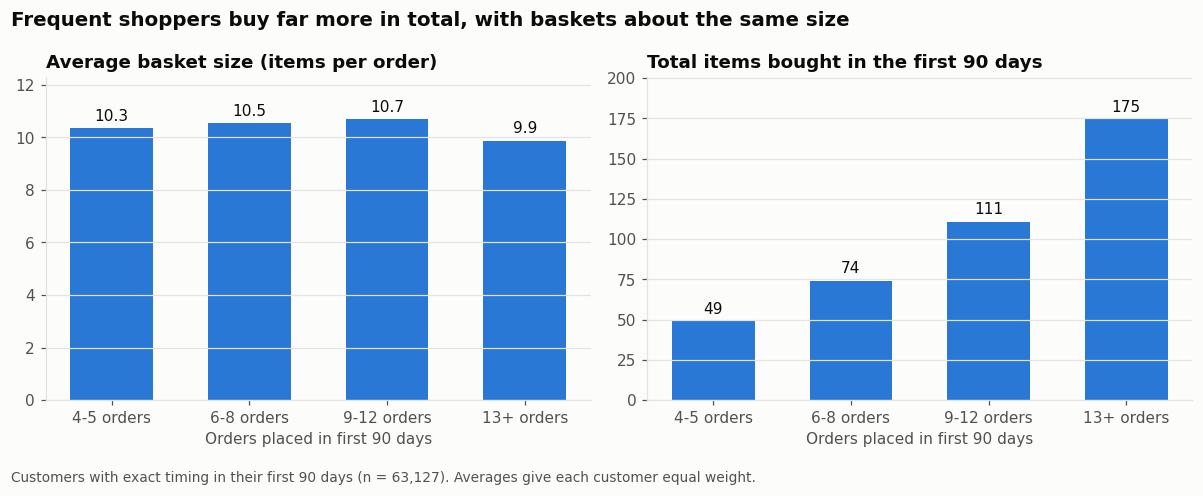

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
x = range(len(seg_order))

for ax, col, title, fmt in [
    (axes[0], 'avg_basket_size', 'Average basket size (items per order)', '{:.1f}'),
    (axes[1], 'avg_items_90d', 'Total items bought in the first 90 days', '{:.0f}'),
]:
    bars = ax.bar(x, q1_main[col], color=MAIN_COLOR, width=0.6)
    ax.bar_label(bars, labels=[fmt.format(v) for v in q1_main[col]], padding=3, color=INK, fontsize=10)
    ax.set_xticks(list(x))
    ax.set_xticklabels(seg_order)
    ax.set_xlabel('Orders placed in first 90 days')
    ax.set_title(title, loc='left')
    ax.grid(axis='x', visible=False)
    ax.set_ylim(0, q1_main[col].max() * 1.15)

fig.suptitle('Frequent shoppers buy far more in total, with baskets about the same size',
             x=0.01, ha='left', fontsize=13, fontweight='bold')
fig.text(0.01, -0.04, f'Customers with exact timing in their first 90 days (n = {len(q1_exact):,}). '
         'Averages give each customer equal weight.', color=INK_2, fontsize=9)
fig.tight_layout()
save(fig, '05_frequency_vs_volume.png')
plt.show()

In [16]:
low, high = q1_main.loc['4-5 orders'], q1_main.loc['13+ orders']
print(f"Items in 90 days: {low.avg_items_90d:.0f} (4-5 orders) vs {high.avg_items_90d:.0f} (13+ orders) "
      f"-> {high.avg_items_90d / low.avg_items_90d:.1f}x")
print(f"Orders: {high.avg_orders / low.avg_orders:.1f}x more | basket size: {low.avg_basket_size:.1f} vs {high.avg_basket_size:.1f} items")

Items in 90 days: 49 (4-5 orders) vs 175 (13+ orders) -> 3.6x
Orders: 3.8x more | basket size: 10.3 vs 9.9 items


**Q1 findings**

- **Yes, more frequent shoppers buy much more overall.** Customers placing 13+ orders in their first 90 days bought about **3.6x as many items** (175 vs 49) as customers placing 4-5 orders.
- **Basket size hardly varies between segments** (about 9.9-10.7 items). The most frequent group's baskets are only about 0.5 items smaller than the least frequent group's, which is tiny next to the 3.8x gap in order count. In this data, total volume is driven almost entirely by **how often** someone shops.
- The sensitivity check (all 149,635 customers) shows the same pattern.
- **Caveats:** the 30-day cap hides genuinely infrequent (less than monthly) shoppers, and the window covers only the first 90 *observed* days. Customers whose history ends before day 90 are excluded.

## 6. Verification

The checks below confirm that the notebook's figures agree with the SQL output, and that the row counts match the documented exclusions.

In [17]:
checks = {
    'Q2-Q4 customers = 88,202': len(w) == 88202,
    'Every customer has at least one short and one long order': ((w['n_orders', 'short'] >= 1) & (w['n_orders', 'long'] >= 1)).all(),
    'Orders compared = 1,358,167': total_orders == 1358167,
    'Q1 eligible customers = 149,635': len(q1) == 149635,
    'Q1 exact-timing customers = 63,127': len(q1_exact) == 63127,
    'Q1 minimum orders in window = 4 (consequence of 30-day cap)': q1['orders_in_window'].min() == 4,
    'Q2 short/long averages match SQL (7.73 / 10.11)': (round(q2.iloc[1, 0], 2), round(q2.iloc[2, 0], 2)) == (7.73, 10.11),
    'Category shares are between 0 and 100': all(w[f'{c}_share'].stack().between(0, 100).all() for c in CATS),
}
pd.Series(checks, name='passed').to_frame()

,passed
"Q2-Q4 customers = 88,202",True
Every customer has at least one short and one long order,True
"Orders compared = 1,358,167",True
"Q1 eligible customers = 149,635",True
"Q1 exact-timing customers = 63,127",True
Q1 minimum orders in window = 4 (consequence of 30-day cap),True
Q2 short/long averages match SQL (7.73 / 10.11),True
Category shares are between 0 and 100,True


## 7. Summary of findings

| Question | Answer | Key numbers |
|---|---|---|
| Q2 Basket size | The same customer's basket is **bigger after a long wait** | 7.7 → 10.1 items (+2.4, median +1.7); 71% of customers |
| Q3 Category mix | **Barely changes**; slight tilt towards staples | Produce +1.1 pts, yogurt +0.6, milk +0.3, eggs +0.2, snacks -0.3 |
| Q4 Presence & diversity | Every category more likely to appear; +1.5 aisles, **mostly because the basket is bigger** | Yogurt 17.7% → 25.8% of orders; aisles at equal size nearly identical |
| Q1 (context) Frequency vs volume | More frequent shoppers buy **far more in total**; basket size barely changes | 13+ orders: 175 items in 90 days vs 49 for 4-5 orders (3.6x); baskets ~10 items in every segment |

**Bottom line:** how often someone shops is linked to *how much* they buy, both per order (within a customer) and in total (across customers). It's linked only slightly to *what* they buy.

## 8. Limitations

- **Association, not causation.** The data shows what happens around long and short gaps, not why. Trip purpose (stock-up vs top-up), household size and promotions can't be observed.
- **30-day cap.** "30" means "30 or more". Truly infrequent shoppers can't be identified (Q1), and the long group mixes 8-day and multi-month gaps (Q2-Q4). Excluding capped orders didn't change the Q2 result.
- **Partial histories and no dates.** Each customer has 4-100 orders, with no calendar dates and no seasonality.
- **Excluded orders.** The 75,000 test orders (no contents), first orders, same-day orders and the 4-7 day band are excluded from Q2-Q4.
- **Who is analyzed.** Q2-Q4 cover the 88,202 customers (43%) with both short and long orders, and Q1 covers customers with exact timing in their first 90 days. These groups lean towards more frequent shoppers.
- **Item counts, not spend.** The dataset has no prices or quantities: an "item" is one product line in the cart.
- **Small categories.** Seafood (0.16% of items) and poultry (0.8%) are rare, so their numbers are less reliable.